# Gymnasium CPU Playground

**WalkingLab × Hands-On Modern RL companion experiment notebook**

Run the same curated Gymnasium recipes as the Studio, from bandits and grids to control tasks.

- Resource profile: **CPU**
- Quick run in this notebook: **2,000** training units
- Full experiment: Use each task's default budget from EXPERIMENTS for a full comparison
- [Live ModelScope Studio](https://modelscope.cn/studios/walkinglab/hands-on-modern-rl-experiment-gymnasium)
- [Experiment source](https://github.com/walkinglabs/hands-on-modern-rl/tree/main/modelscope-space/hands-on-modern-rl-experiment-gymnasium)
- [Hands-On Modern RL](https://github.com/walkinglabs/hands-on-modern-rl) · [WalkingLab](https://modelscope.cn/organization/walkinglab)

The notebook imports the exact runtime used by the Studio. Change the parameters below, run the cells in order,
and compare the checkpoint curve with the final policy GIF or result image. The first setup can take longer because
native environments and simulator assets are cached; later runs reuse `/mnt/workspace/hands-on-modern-rl-notebooks`.


## 1. Experiment and training schedule

This experiment asks whether the selected policy improves on the task's evaluation metric as its training budget
increases. Start with the quick budget to verify the environment and logs. Then increase the budget only after the
complete result cell produces a curve and an artifact.

A normal ModelScope **CPU Notebook** is sufficient; no GPU is required.

Compare the evaluation curve and replay at each checkpoint. Increase the budget above for a longer training run.


## 2. Prepare the matching Studio runtime


In [1]:
from __future__ import annotations

import hashlib
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

REPOSITORY_URL = "https://github.com/walkinglabs/hands-on-modern-rl.git"
SPACE_SLUG = "hands-on-modern-rl-experiment-gymnasium"
INSTALL_DEPENDENCIES = os.getenv("HANDS_ON_LAB_PREINSTALLED") != "1"

def locate_or_clone_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "modelscope-space" / SPACE_SLUG).is_dir():
            return candidate
    workspace = Path("/mnt/workspace") if Path("/mnt/workspace").is_dir() else Path.cwd()
    target = workspace / "hands-on-modern-rl-notebooks" / "source"
    target.parent.mkdir(parents=True, exist_ok=True)
    if (target / ".git").is_dir():
        subprocess.run(["git", "-C", str(target), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL, str(target)], check=True)
    return target

REPO_ROOT = locate_or_clone_repo()
SPACE_DIR = REPO_ROOT / "modelscope-space" / SPACE_SLUG
requirements = SPACE_DIR / "requirements.txt"
packages = SPACE_DIR / "packages.txt"
cache_root = Path("/mnt/workspace/hands-on-modern-rl-notebooks") if Path("/mnt/workspace").is_dir() else REPO_ROOT / ".cache" / "online-experiments"
cache_root.mkdir(parents=True, exist_ok=True)
digest = hashlib.sha256(requirements.read_bytes() + (packages.read_bytes() if packages.exists() else b"")).hexdigest()[:12]
marker = cache_root / f"{SPACE_SLUG}-{digest}.ready"

if INSTALL_DEPENDENCIES and not marker.exists():
    if packages.exists() and sys.platform.startswith("linux") and hasattr(os, "geteuid") and os.geteuid() == 0:
        system_packages = [line.strip() for line in packages.read_text().splitlines() if line.strip() and not line.startswith("#")]
        subprocess.run(["apt-get", "update"], check=True)
        subprocess.run(["apt-get", "install", "-y", "--no-install-recommends", *system_packages], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "-r", str(requirements)], check=True)
    marker.touch()
else:
    print(f"Dependency cache ready: {marker}")

if importlib.util.find_spec("ipywidgets") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "ipywidgets>=8,<9"],
        check=True,
    )

os.chdir(SPACE_DIR)
if str(SPACE_DIR) not in sys.path:
    sys.path.insert(0, str(SPACE_DIR))
print(f"Repository: {REPO_ROOT}")
print(f"Experiment runtime: {SPACE_DIR}")


Dependency cache ready: /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-en/workspaces/gymnasium/.cache/online-experiments/hands-on-modern-rl-experiment-gymnasium-75bfe84ee278.ready
Repository: /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-en/workspaces/gymnasium
Experiment runtime: /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-en/workspaces/gymnasium/modelscope-space/hands-on-modern-rl-experiment-gymnasium


## 3. Configure the epoch schedule


In [2]:
import app as playground

EXPERIMENT = "Bandit · ε-greedy"
STEPS_PER_EPOCH = 1000
EPOCHS = 2
LEARNING_RATE = 0.1
GAMMA = 0.99
EPSILON = 0.10
SEED = 42

print("Curated experiments:")
for name in playground.EXPERIMENTS:
    print(" ", name)
if EXPERIMENT not in playground.EXPERIMENTS:
    raise ValueError(f"Choose EXPERIMENT from {list(playground.EXPERIMENTS)}")
print(f"Epoch schedule: {EPOCHS} epochs × {STEPS_PER_EPOCH:,} steps")


Curated experiments:
  Bandit · ε-greedy
  Blackjack · Monte Carlo
  GridWorld · Q-Learning
  FrozenLake · Q-Learning
  CliffWalking · SARSA
  Taxi · Q-Learning
  CartPole · DQN
  CartPole · PPO
  MountainCar · Tabular Q
  Acrobot · PPO
  Pendulum · PPO
  MountainCarContinuous · SAC
Epoch schedule: 2 epochs × 1,000 steps


## 4. Train and save one model per epoch


In [3]:
import html as html_module
import re
from IPython.display import Image as NotebookImage, display

results = []
for result in playground.train(
    EXPERIMENT, STEPS_PER_EPOCH, EPOCHS, LEARNING_RATE, GAMMA, EPSILON, SEED, "English"
):
    results.append(result)
    console = result[-1]
    value = getattr(console, "value", str(console))
    text = html_module.unescape(re.sub(r"<[^>]+>", "", str(value)))
    print(text[-1800:], flush=True)

if not results:
    raise RuntimeError("The playground returned no training result")
status, metric, curve, preview, artifact, console = results[-1]
display(curve)
print("Result artifact:", getattr(artifact, "value", artifact))
print(f"Saved {{len(playground.load_models(EXPERIMENT))}} selectable epoch models for this task.")


Matplotlib is building the font cache; this may take a moment.



    
      Live training log
      Multi-Armed Bandit training console
    0.0s  CONFIG  steps=2000 epochs=2 alpha=0.1 epsilon=0.1 seed=42
   11.5s  EPOCH   1/2 step=1000/2000 average_reward=0.665 best_arm=3
   11.5s  SAVE    model_id=1792630667-472000-epoch-01
    
    



    
      Live training log
      Multi-Armed Bandit training console
    0.0s  CONFIG  steps=2000 epochs=2 alpha=0.1 epsilon=0.1 seed=42
   11.5s  EPOCH   1/2 step=1000/2000 average_reward=0.665 best_arm=3
   11.5s  SAVE    model_id=1792630667-472000-epoch-01
   11.6s  EPOCH   2/2 step=2000/2000 average_reward=0.723 best_arm=3
   11.6s  SAVE    model_id=1792630667-472000-epoch-02
    
    



    
      Live training log
      Multi-Armed Bandit training console
    0.0s  CONFIG  steps=2000 epochs=2 alpha=0.1 epsilon=0.1 seed=42
   11.5s  EPOCH   1/2 step=1000/2000 average_reward=0.665 best_arm=3
   11.5s  SAVE    model_id=1792630667-472000-epoch-01
   11.6s  EPOCH   2/2 step=2000/2000 average_reward=0.723 best_arm=3
   11.6s  SAVE    model_id=1792630667-472000-epoch-02
    
    


<Figure size 820x400 with 1 Axes>

Result artifact: /Users/sanbu/Documents/Codex/2026-10-20/revie/work/chapter-lab-runs/studio-en/workspaces/gymnasium/modelscope-space/hands-on-modern-rl-experiment-gymnasium/artifacts/bandit-run-summary.json
Saved {len(playground.load_models(EXPERIMENT))} selectable epoch models for this task.


## 5. Load a saved epoch model and run inference

The selector reloads models produced in this Notebook workspace. The live Studio uses a separate container.


In [4]:
from pathlib import Path
from IPython.display import Image as NotebookImage, clear_output, display
import ipywidgets as widgets

trained_models = playground.load_models(EXPERIMENT)
if not trained_models:
    raise RuntimeError("No saved epoch model was found. Run the training cell above first.")

def model_label(record):
    return (
        f"Epoch {record['epoch']}/{record['epochs']} · {record['step']:,}/{record['total']:,} steps · "
        f"score {record['score']:.2f} · {record['model_id']}"
    )

model_by_id = {record["model_id"]: record for record in trained_models}
model_picker = widgets.Dropdown(
    options=[(model_label(record), record["model_id"]) for record in trained_models],
    value=trained_models[0]["model_id"],
    description="Epoch model:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "110px"},
)
visualize_button = widgets.Button(
    description="Visualize selected policy", button_style="primary", icon="play",
    layout=widgets.Layout(width="240px"),
)
inference_output = widgets.Output()

def visualize_selected(_=None):
    record = model_by_id[model_picker.value]
    with inference_output:
        clear_output(wait=True)
        print("Loading saved model:", record["model"])
        preview = Path(str(record["preview"]))
        if preview.is_file():
            display(NotebookImage(filename=str(preview)))
        else:
            print("The saved policy has no replay file.")
        print("Epoch:", f"{record['epoch']}/{record['epochs']}")
        print("Training step:", f"{record['step']:,}")
        print("Evaluation score:", record["score"])

visualize_button.on_click(visualize_selected)
display(widgets.VBox([model_picker, visualize_button, inference_output]))
print("The newest epoch is selected by default. Choose another saved model, then click Visualize selected policy.")


The newest epoch is selected by default. Choose another saved model, then click Visualize selected policy.


## 6. Read the result before increasing the budget

Compare the first and last checkpoint values, then inspect the replay. A rising curve with an implausible replay can
help locate differences in reward, evaluation and rendering. Continue with **Use each task's default budget from EXPERIMENTS for a full comparison**, keep the seed fixed,
and compare at least three seeds before drawing a conclusion.


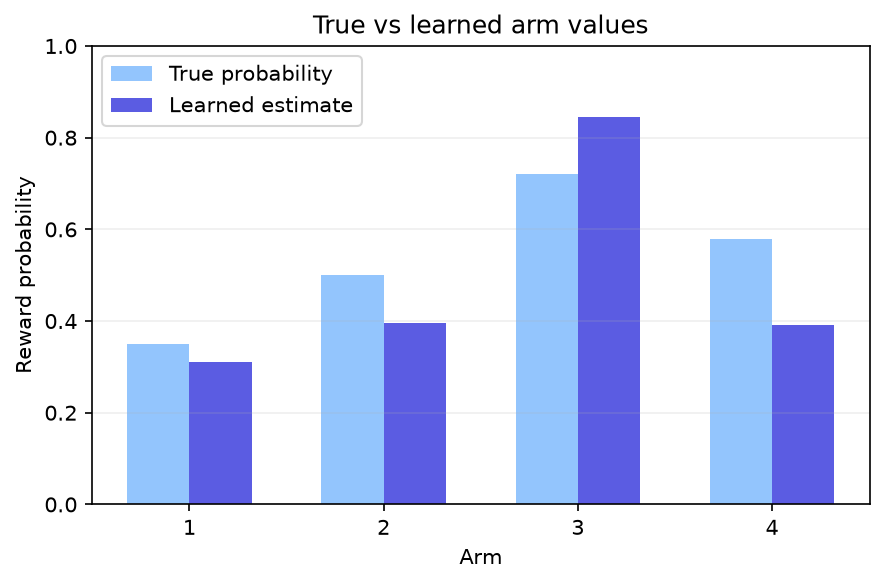

{
  "score": 0.723,
  "steps": 2000,
  "epochs": 2,
  "checkpoints": 2,
  "preview": "learned-policy.png"
}


In [5]:
import json
from IPython.display import Image as NotebookImage, display

records = epoch_models if "epoch_models" in globals() else trained_models
assert records, "Training must produce a saved checkpoint"
latest = max(records, key=lambda record: (record.get("created_ns", 0), record.get("step", 0)))
preview = Path(str(latest.get("preview", "")))
assert preview.is_file(), "Training must produce a replay or result image"
display(NotebookImage(filename=str(preview)))
output_id = os.getenv("HANDS_ON_LAB_ID", SPACE_SLUG)
output = Path(os.getenv("HANDS_ON_LAB_OUTPUT", str(cache_root / "results"))) / output_id
output.mkdir(parents=True, exist_ok=True)
metrics = {"score": latest.get("score"), "steps": latest.get("step"),
           "epochs": EPOCHS, "checkpoints": len(records), "preview": preview.name}
(output / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))


## Saved run results

CPU · Python 3.12.13 · 37.41 s

[Open the full result page](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/gymnasium-en.html)
